# 3 · Building change in Blatten: 19 May → 30 May 2025

This notebook applies the change detector trained in notebook 2 to the swisstopo Rapid Mapping
orthophotos before and after the ice-rock avalanche of 28 May 2025. It follows the application pages of
L10: run the model on the pair (page 5), read and threshold its output (pages 6–7), compare it with a
pixel-wise baseline (page 7), export GIS-ready polygons (page 7), and validate the result (page 9).

Blatten was never used for training, checkpoint selection or threshold tuning, so the scores below
show how well the model transfers to the real event.

## A. Imports, settings and the selected model

In [1]:
import json
import time
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import torch
from matplotlib.patches import Patch
from rasterio.features import rasterize, shapes
from shapely.geometry import shape
from scipy.ndimage import binary_dilation
from skimage.filters import threshold_otsu

from torchgeo.tasks import ChangeDetection

warnings.filterwarnings("ignore")

# ============================ SETTINGS =======================================
PRE, POST = "2025-05-19", "2025-05-30"  # Rapid Mapping dates (T1 before, T2 after)
TILE_SIZE = 256  # tiled inference: tile size in pixels (= training chip size)
OVERLAP = 64  # neighbouring tiles overlap; probabilities in the overlap are averaged
MIN_AREA_M2 = 10  # smallest change polygon kept in the GIS export
DESTROYED_IF_FLAGGED = 0.5  # a building counts as "detected as changed" if ≥ 50% of its footprint is flagged
REMOVED_IF_OVERLAP_BELOW = 0.2  # reference: a pre-event footprint is "removed" if < 20% of it is still in TLM 2026
# ==============================================================================

# Notebooks live in notebooks/; data/ and outputs/ sit one level up (project root).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data/processed"
RAW = ROOT / "data/raw"
OUT_DIR = ROOT / "outputs/results"
FIGURES = ROOT / "outputs/figures"
OUT_DIR.mkdir(exist_ok=True)

selected = json.loads((ROOT / "outputs/runs/selected_model.json").read_text())
THRESHOLD = selected["threshold"]
MEAN = torch.tensor(selected["mean"]).view(1, 3, 1, 1)
STD = torch.tensor(selected["std"]).view(1, 3, 1, 1)
model = ChangeDetection.load_from_checkpoint(ROOT / selected["checkpoint"], map_location="cpu").eval()
print(f"Model: {selected['experiment']}")
print(f"Threshold chosen on the validation set (Wiler): {THRESHOLD}")

.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model: fcsiamdiff-resnet18_p256_aug1_same0.3_photo1_dice_freeze0_lr0.001_n512_ep80_seed0
Threshold chosen on the validation set (Wiler): 0.02


## B. The image pair

Grid: 4800 x 3900 px at 0.5 m, EPSG:2056; valid on both dates: 72.2%


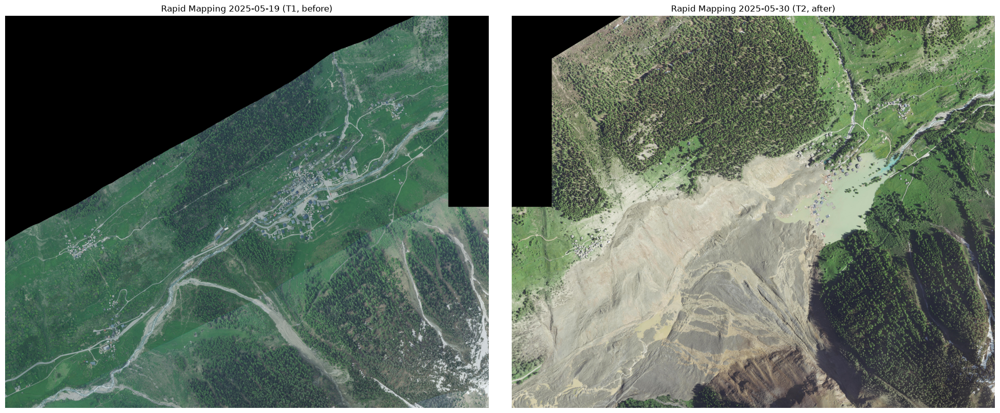

In [2]:
def read_image(path):
    """Return the bands, transform and CRS of a GeoTIFF."""
    with rasterio.open(path) as src:
        return src.read(), src.transform, src.crs


pre, transform, crs = read_image(PROCESSED / f"rapid_{PRE}_blatten.tif")
post, _, _ = read_image(PROCESSED / f"rapid_{POST}_blatten.tif")
swissimage, _, _ = read_image(PROCESSED / "swissimage2023_blatten.tif")
valid = (pre.max(axis=0) > 0) & (post.max(axis=0) > 0)
PIXEL_AREA_M2 = transform.a * -transform.e
extent = [transform.c, transform.c + transform.a * pre.shape[2], transform.f + transform.e * pre.shape[1], transform.f]
print(f"Grid: {pre.shape[2]} x {pre.shape[1]} px at {transform.a} m, {crs}; valid on both dates: {100 * valid.mean():.1f}%")


def rgb(image):
    return np.moveaxis(image, 0, -1)


fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, image, title in zip(axes, [pre, post], [f"Rapid Mapping {PRE} (T1, before)", f"Rapid Mapping {POST} (T2, after)"]):
    ax.imshow(rgb(image), extent=extent)
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

The debris of the collapse covers the centre of the scene, where the village core of Blatten stood.
Upstream (right), the Lonza was dammed and a lake formed over part of the village. Weissenried on the
slope to the left and the eastern hamlets are outside the debris.

## C. Run change detection: tiled inference (page 5)

The model was trained on 256 × 256 chips, so the 4800 × 3900-pixel scene is processed in overlapping
tiles, and the probabilities of overlapping tiles are averaged to avoid seams, the same tiled inference
as `ChangeStarDetection.predict()` (`tile_size`, `overlap`). Each tile is normalized with the band
statistics of the **training** chips.

In [3]:
def predict_change(image1, image2, tile_size=TILE_SIZE, overlap=OVERLAP, batch_size=8):
    """Tiled FC-Siam-diff inference; returns a change probability per pixel."""
    _, height, width = image1.shape
    stride = tile_size - overlap
    pad_h = (-(height - tile_size) % stride) if height > tile_size else tile_size - height
    pad_w = (-(width - tile_size) % stride) if width > tile_size else tile_size - width
    pair = np.stack([image1, image2]).astype("float32")  # (T, C, H, W)
    # Pad (by reflection) so that whole tiles cover the image, cut back at the end
    pair = np.pad(pair, ((0, 0), (0, 0), (0, pad_h), (0, pad_w)), mode="reflect")
    prob_sum = np.zeros(pair.shape[-2:], dtype="float32")
    count = np.zeros(pair.shape[-2:], dtype="float32")
    corners = [(r, c) for r in range(0, pair.shape[-2] - tile_size + 1, stride)
               for c in range(0, pair.shape[-1] - tile_size + 1, stride)]
    for i in range(0, len(corners), batch_size):
        batch = [pair[:, :, r:r + tile_size, c:c + tile_size] for r, c in corners[i:i + batch_size]]
        x = (torch.from_numpy(np.stack(batch)) - MEAN.unsqueeze(1)) / STD.unsqueeze(1)  # (B, T, C, H, W)
        with torch.no_grad():
            prob = model.predict_step({"image": x}, 0)[:, 0].numpy()
        for (r, c), p in zip(corners[i:i + batch_size], prob):
            prob_sum[r:r + tile_size, c:c + tile_size] += p
            count[r:r + tile_size, c:c + tile_size] += 1
    return (prob_sum / count)[:height, :width]


def save_raster(array, path, dtype, nodata=None):
    """Write a single-band array on the Blatten grid as a compressed GeoTIFF."""
    profile = dict(driver="GTiff", width=array.shape[1], height=array.shape[0], count=1, dtype=dtype,
                   crs=crs, transform=transform, compress="deflate", nodata=nodata)
    with rasterio.open(path, "w", **profile) as dst:
        dst.write(array.astype(dtype), 1)


start = time.time()
change_prob = predict_change(pre, post)
change_prob[~valid] = 0
change_map = (change_prob > THRESHOLD) & valid
print(f"Prediction took {time.time() - start:.0f} s")

save_raster(np.where(valid, change_prob, -1), OUT_DIR / "change_probability.tif", "float32", nodata=-1)
save_raster(np.where(valid, change_map, 255), OUT_DIR / "change_map.tif", "uint8", nodata=255)
print(f"Changed area at threshold {THRESHOLD}: {change_map.sum() * PIXEL_AREA_M2:,.0f} m² "
      f"({100 * change_map[valid].mean():.2f}% of the valid area)")

Prediction took 78 s


Changed area at threshold 0.02: 48,824 m² (1.45% of the valid area)


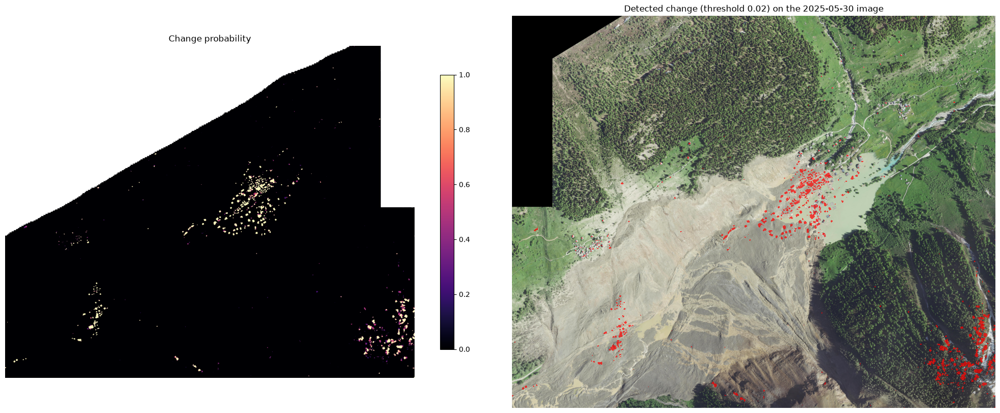

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
im = axes[0].imshow(np.ma.masked_where(~valid, change_prob), cmap="magma", vmin=0, vmax=1, extent=extent)
axes[0].set_title("Change probability")
plt.colorbar(im, ax=axes[0], shrink=0.7)
axes[1].imshow(rgb(post), extent=extent)
axes[1].imshow(np.ma.masked_equal(change_map, 0), cmap="autumn", alpha=0.7, extent=extent, interpolation="nearest")
axes[1].set_title(f"Detected change (threshold {THRESHOLD}) on the {POST} image")
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
plt.savefig(FIGURES / "03_change_map.png", dpi=120, bbox_inches="tight")
plt.show()

## D. A reference for validation (page 9)

Page 9 asks for a validation plan. Besides spot-checks, an independent reference is available
because swisstopo updated swissTLM3D after the event. A pre-event footprint (release 2025-03) that has
(almost) no counterpart in the first post-event release (2026-02) was removed from the topographic model.
We use those footprints as the **reference change**: buildings destroyed or buried.

Limits of this reference:

- The 2026-02 release reflects swisstopo's mapping until about October 2025, not exactly 30 May. A house
  standing on 30 May but demolished in summer would count as "removed".
- A house that is badly damaged but still mapped counts as "not removed".
- A house under water may still be visible on 30 May, or may have been mapped as removed.

The reference is therefore an independent approximation, not ground truth.

reference  removed  standing
evaluable                   
False            0        17
True           377       191


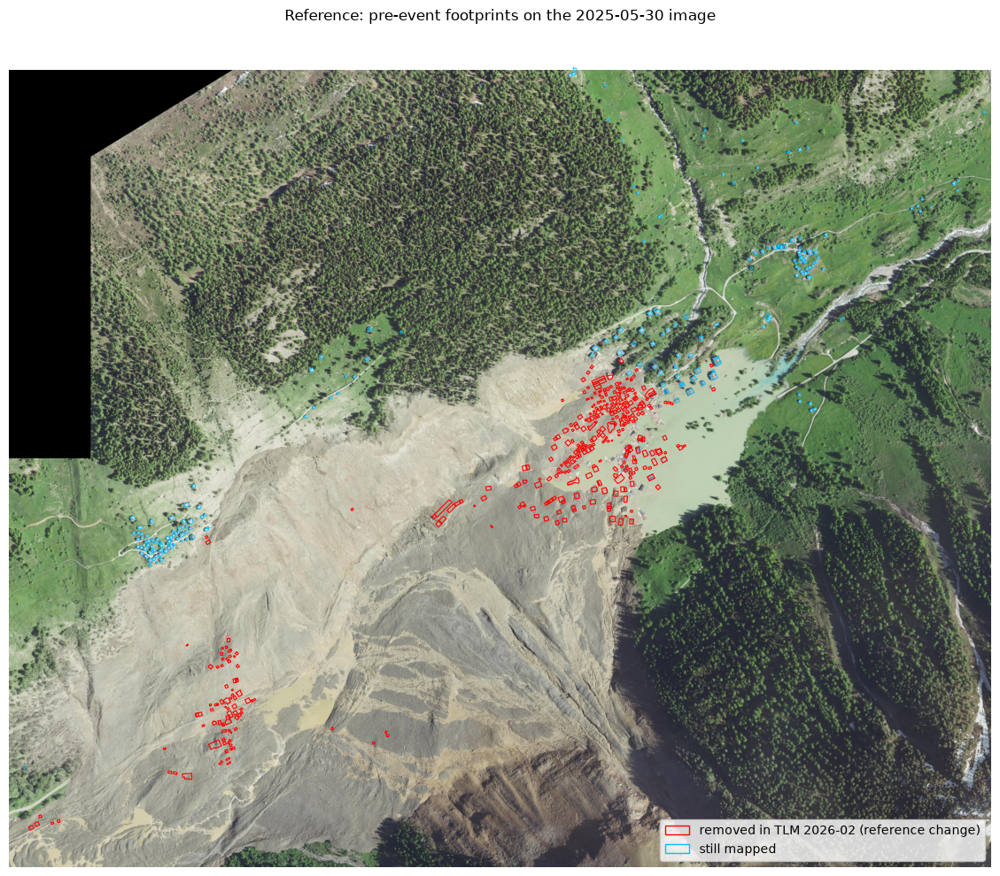

In [5]:
BUILDING_TYPES = ["Gebaeude", "Offenes Gebaeude", "Kapelle", "Sakrales Gebaeude", "Im Bau", "Sakraler Turm"]
xmin, ymin, xmax, ymax = extent[0], extent[2], extent[1], extent[3]
tlm_pre = gpd.read_file(RAW / "tlm_buildings_2025-03.gpkg").cx[xmin:xmax, ymin:ymax]
tlm_post = gpd.read_file(RAW / "tlm_buildings_2026-02.gpkg").cx[xmin:xmax, ymin:ymax]
tlm_pre = tlm_pre[tlm_pre["OBJEKTART"].isin(BUILDING_TYPES)].reset_index(drop=True)
tlm_post = tlm_post[tlm_post["OBJEKTART"].isin(BUILDING_TYPES)]

post_union = tlm_post.union_all()
tlm_pre["area_m2"] = tlm_pre.area
tlm_pre["still_mapped"] = tlm_pre.intersection(post_union).area / tlm_pre["area_m2"]
tlm_pre["reference"] = np.where(tlm_pre["still_mapped"] < REMOVED_IF_OVERLAP_BELOW, "removed", "standing")

# Which buildings can be evaluated at all? Those fully covered by valid imagery on both dates.
pixel_ids = rasterize(((g, i + 1) for i, g in enumerate(tlm_pre.geometry)), out_shape=valid.shape,
                      transform=transform, fill=0, dtype="int32")
ids = np.arange(1, len(tlm_pre) + 1)
pixels_total = np.bincount(pixel_ids.ravel(), minlength=len(tlm_pre) + 1)[ids]
pixels_valid = np.bincount(pixel_ids[valid].ravel(), minlength=len(tlm_pre) + 1)[ids]
tlm_pre["evaluable"] = (pixels_total > 0) & (pixels_valid == pixels_total)

print(tlm_pre.groupby(["evaluable", "reference"]).size().unstack(fill_value=0))

reference_change = rasterize(((g, 1) for g in tlm_pre.loc[tlm_pre.reference == "removed"].geometry),
                             out_shape=valid.shape, transform=transform, fill=0, dtype="uint8").astype(bool)

fig, ax = plt.subplots(figsize=(14, 10))
ax.imshow(rgb(post), extent=extent)
tlm_pre[tlm_pre.reference == "standing"].plot(ax=ax, facecolor="none", edgecolor="deepskyblue", linewidth=0.6)
tlm_pre[tlm_pre.reference == "removed"].plot(ax=ax, facecolor="none", edgecolor="red", linewidth=0.8)
ax.legend(handles=[Patch(edgecolor="red", facecolor="none", label="removed in TLM 2026-02 (reference change)"),
                   Patch(edgecolor="deepskyblue", facecolor="none", label="still mapped")], loc="lower right")
ax.set_title(f"Reference: pre-event footprints on the {POST} image")
ax.set_axis_off()
plt.tight_layout()
plt.savefig(FIGURES / "03_reference.png", dpi=120, bbox_inches="tight")
plt.show()

## E. How good is the change map?

Two complementary views, both computed only where both images are valid:

- **Pixel level** (page 4, step E): precision, recall, F1 and IoU of the change class. The reference
  change is the removed footprints; pixels outside any pre-event footprint count as "no change", so every
  flagged pixel on rock, meadow or debris is a false alarm.
- **Building level**: for each pre-event building, which share of its footprint did the model flag? A
  building is "detected as changed" if at least half of its footprint is flagged. This answers the
  project question, *which houses were lost?*, more directly than pixels do.

In [6]:
def pixel_scores(pred, reference, mask=valid):
    """Pixel-level scores of the change class inside `mask`."""
    pred, reference = pred[mask], reference[mask]
    tp = int((pred & reference).sum())
    fp = int((pred & ~reference).sum())
    fn = int((~pred & reference).sum())
    tn = int((~pred & ~reference).sum())
    return {"Accuracy": (tp + tn) / (tp + fp + fn + tn), "Precision": tp / max(tp + fp, 1),
            "Recall": tp / max(tp + fn, 1), "F1-score": 2 * tp / max(2 * tp + fp + fn, 1),
            "IoU": tp / max(tp + fp + fn, 1)}


def building_scores(pred, buildings=tlm_pre):
    """Share of each footprint flagged, and building-level scores for the evaluable buildings."""
    flagged = np.bincount(pixel_ids[pred].ravel(), minlength=len(buildings) + 1)[ids] / np.maximum(pixels_total, 1)
    detected = flagged >= DESTROYED_IF_FLAGGED
    removed = (buildings["reference"] == "removed").to_numpy()
    use = buildings["evaluable"].to_numpy()
    tp, fp = int((detected & removed & use).sum()), int((detected & ~removed & use).sum())
    fn, tn = int((~detected & removed & use).sum()), int((~detected & ~removed & use).sum())
    return flagged, {"removed, detected (TP)": tp, "standing, flagged (FP)": fp, "removed, missed (FN)": fn,
                     "standing, not flagged (TN)": tn, "Precision": tp / max(tp + fp, 1),
                     "Recall": tp / max(tp + fn, 1), "F1-score": 2 * tp / max(2 * tp + fp + fn, 1)}


tlm_pre["flagged_fraction"], building_result = building_scores(change_map)
evaluation = pd.DataFrame({"FC-Siam-diff, pixels": pixel_scores(change_map, reference_change)}).T
display(evaluation.round(3))
pd.Series(building_result, name="FC-Siam-diff, buildings").to_frame().T.round(3)

,Accuracy,Precision,Recall,F1-score,IoU
"FC-Siam-diff, pixels",0.988,0.311,0.732,0.436,0.279


,"removed, detected (TP)","standing, flagged (FP)","removed, missed (FN)","standing, not flagged (TN)",Precision,Recall,F1-score
"FC-Siam-diff, buildings",289.0,33.0,88.0,158.0,0.898,0.767,0.827


Accuracy is listed only to show again why it is useless here (page 4): nearly every pixel is
"unchanged". At pixel level, note that recall is limited by design: the reference contains the *whole*
footprint, while the model can only flag what it can see.

Where do the false alarms (flagged pixels outside removed footprints) lie?

In [7]:
standing_ids = np.flatnonzero(tlm_pre["reference"].to_numpy() == "standing") + 1
on_standing = np.isin(pixel_ids, standing_ids)
near_removed = binary_dilation(reference_change, iterations=6)  # within 3 m of a removed footprint
false_alarm = change_map & ~reference_change & valid
where = pd.Series({
    "within 3 m of a removed footprint (blob edges)": (false_alarm & near_removed).sum(),
    "on a standing building": (false_alarm & on_standing & ~near_removed).sum(),
    "away from any building (debris, lake, snow)": (false_alarm & ~near_removed & ~on_standing).sum(),
}) * PIXEL_AREA_M2
where.to_frame("false-alarm area (m²)").assign(share=lambda d: d.iloc[:, 0] / d.iloc[:, 0].sum()).round(2)

,false-alarm area (m²),share
within 3 m of a removed footprint (blob edges),5384.00,0.16
on a standing building,1386.75,0.04
"away from any building (debris, lake, snow)",26873.50,0.80


**Result.** The building level answers the project question more directly than the pixel level:

- **Buildings:** 289 of the 377 removed buildings are detected (recall 0.77) and 33 of 191 standing
  buildings are wrongly flagged (precision 0.90), building F1 = 0.83. Most standing buildings have
  nothing flagged at all (median flagged share 0%).
- **Pixels:** F1 = 0.44, IoU = 0.28. Recall (0.73) is close to the building recall, but precision is only
  0.31. The breakdown above shows why: about 80% of the false-alarm area lies **away from any building**,
  on surfaces the model never saw in training: the boulders and lobes of the debris field, objects in the
  lake, and above all melting snow patches in the forest on the east slope (about 19,000 m² in the
  south-east corner alone; on 19 May the north-facing slope was still partly snow-covered).
  Bright, roof-sized patches that disappear look exactly like a removed building to a model trained only on building/no-building pairs.

For a damage inventory these scattered false alarms matter less, because the building-level product
(section H) only looks at pre-event footprints.

## F. Thresholds (page 7)

The threshold was fixed on the validation set in notebook 2. Here we only look at how sensitive the map
is to it, as on page 7. The F1 curve on Blatten is shown as a **diagnostic**: choosing the threshold from
it would be tuning on the test data (page 8, "Choose on validation, report on test").

,changed area (m²),pixel F1,building F1
0.05,45979.25,0.449,0.828
0.20,41572.25,0.471,0.834
0.35,38559.25,0.488,0.835
0.50,34055.00,0.516,0.819
0.65,30494.50,0.533,0.809
0.80,28940.25,0.538,0.804
0.95,26725.00,0.546,0.795


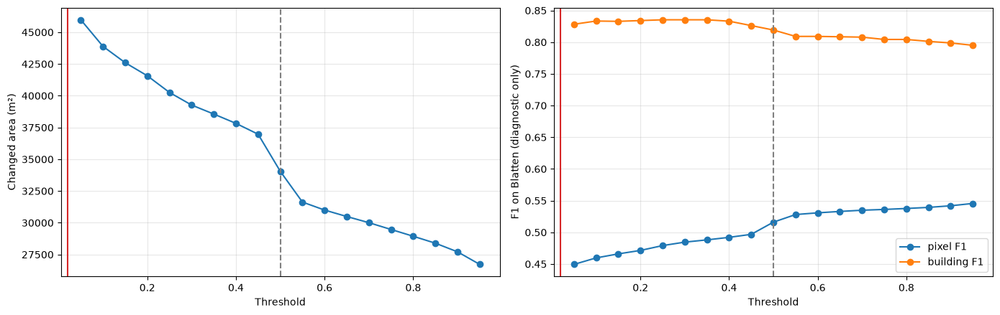

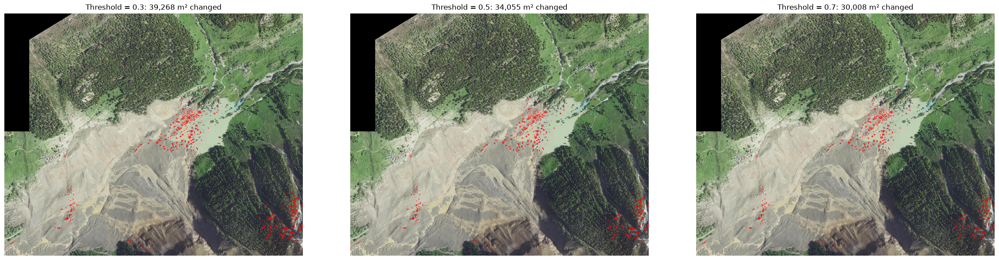

In [8]:
grid = np.round(np.linspace(0.05, 0.95, 19), 2)
sensitivity = pd.DataFrame({
    "changed area (m²)": [((change_prob > t) & valid).sum() * PIXEL_AREA_M2 for t in grid],
    "pixel F1": [pixel_scores((change_prob > t) & valid, reference_change)["F1-score"] for t in grid],
    "building F1": [building_scores((change_prob > t) & valid)[1]["F1-score"] for t in grid],
}, index=grid)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(grid, sensitivity["changed area (m²)"], marker="o")
axes[0].set_ylabel("Changed area (m²)")
axes[1].plot(grid, sensitivity["pixel F1"], marker="o", label="pixel F1")
axes[1].plot(grid, sensitivity["building F1"], marker="o", label="building F1")
axes[1].set_ylabel("F1 on Blatten (diagnostic only)")
axes[1].legend()
display(sensitivity.iloc[::3].round(3))
for ax in axes:
    ax.axvline(THRESHOLD, color="C3", label=f"chosen on validation ({THRESHOLD})")
    ax.axvline(0.5, color="grey", ls="--")
    ax.set_xlabel("Threshold")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(24, 6))
for ax, t in zip(axes, [0.3, 0.5, 0.7]):
    ax.imshow(rgb(post), extent=extent)
    ax.imshow(np.ma.masked_equal((change_prob > t) & valid, 0), cmap="autumn", alpha=0.7, extent=extent, interpolation="nearest")
    ax.set_title(f"Threshold = {t}: {((change_prob > t) & valid).sum() * PIXEL_AREA_M2:,.0f} m² changed")
    ax.set_axis_off()
plt.tight_layout()
plt.show()

**Threshold sensitivity.** As on the validation set, the model's probabilities are almost binary, so the
threshold matters little. Raising it from 0.02 to 0.5 shrinks the changed area from about 49,000 to
34,000 m² and trades building recall (0.77 → 0.73) for precision (0.90 → 0.94); building F1 hardly moves
(0.83 → 0.82), pixel F1 rises from 0.44 to 0.52. The threshold chosen on Wiler is therefore
reasonable for Blatten, and we keep it (changing it now would be tuning on the event).

## G. Better than a simple baseline? (page 7)

The pixel-wise baseline from page 7: length of the RGB change vector, thresholded with Otsu.

In [9]:
# Length of the RGB change vector per pixel, thresholded with Otsu
a, b = pre.astype("float32"), post.astype("float32")
magnitude = np.sqrt(((b - a) ** 2).sum(axis=0))
baseline = (magnitude > threshold_otsu(magnitude[valid])) & valid
_, baseline_buildings = building_scores(baseline)

comparison = pd.DataFrame({
    "FC-Siam-diff": {**pixel_scores(change_map, reference_change), "building F1": building_result["F1-score"],
                     "changed area (m²)": change_map.sum() * PIXEL_AREA_M2},
    "RGB difference + Otsu": {**pixel_scores(baseline, reference_change), "building F1": baseline_buildings["F1-score"],
                              "changed area (m²)": baseline.sum() * PIXEL_AREA_M2},
}).T
comparison.to_csv(OUT_DIR / "evaluation_blatten.csv")
comparison.round(3)

,Accuracy,Precision,Recall,F1-score,IoU,building F1,changed area (m²)
FC-Siam-diff,0.988,0.311,0.732,0.436,0.279,0.827,48823.75
RGB difference + Otsu,0.618,0.004,0.246,0.008,0.004,0.224,1280055.75


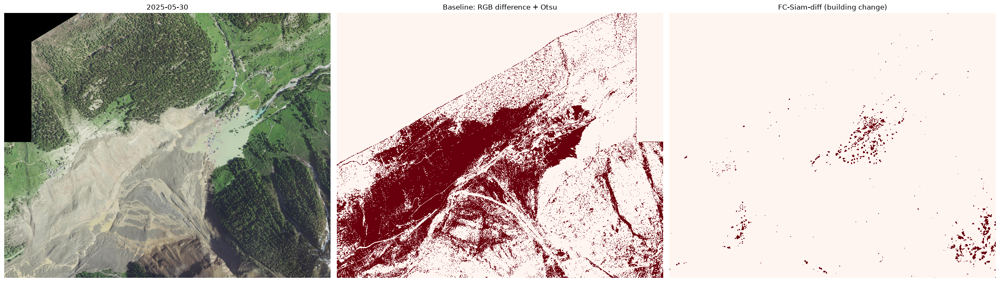

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
axes[0].imshow(rgb(post), extent=extent)
axes[0].set_title(f"{POST}")
axes[1].imshow(baseline, cmap="Reds", interpolation="nearest", extent=extent)
axes[1].set_title("Baseline: RGB difference + Otsu")
axes[2].imshow(change_map, cmap="Reds", interpolation="nearest", extent=extent)
axes[2].set_title("FC-Siam-diff (building change)")
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
plt.show()

The baseline answers a different question: *where does the surface look different?* It flags about
1.3 km², almost 40% of the valid area: the whole debris field, the lake, the snow melt and every shift
in colour and illumination between the two flights. Its pixel F1 (0.01) and building F1
(0.22) show that "something changed" is not the same as "a building changed". The trained model only answers *where did a
building appear or disappear?* Its precision on buildings is what makes it useful for the project
question; its limits come from what it was trained on (see section I).

## H. From pixels to GIS-ready polygons (page 7)

Two exports: the change polygons themselves (with fragments below `MIN_AREA_M2` removed), and the
pre-event building footprints with the share flagged by the model, which is the more useful product for
a damage inventory.

In [11]:
records = [{"change_type": "building change", "geometry": shape(geom)}
           for geom, value in shapes(change_map.astype("uint8"), mask=change_map, transform=transform)]
changes = gpd.GeoDataFrame(records, crs=crs)
changes["area_m2"] = changes.area.round(1)
changes = changes[changes["area_m2"] >= MIN_AREA_M2].reset_index(drop=True)
changes.to_file(OUT_DIR / "change_polygons.gpkg", driver="GPKG")

buildings_out = tlm_pre[["UUID", "OBJEKTART", "area_m2", "evaluable", "reference", "flagged_fraction", "geometry"]].copy()
buildings_out["model"] = np.where(buildings_out["flagged_fraction"] >= DESTROYED_IF_FLAGGED, "changed", "unchanged")
buildings_out.to_file(OUT_DIR / "buildings_pre_event_assessed.gpkg", driver="GPKG")

print(f"{len(changes)} change polygons ≥ {MIN_AREA_M2} m², total {changes.area_m2.sum():,.0f} m², median {changes.area_m2.median():.0f} m²")
pd.crosstab(buildings_out.loc[buildings_out.evaluable, "reference"], buildings_out.loc[buildings_out.evaluable, "model"],
            margins=True)

491 change polygons ≥ 10 m², total 47,773 m², median 42 m²


model,changed,unchanged,All
reference,,,
removed,289,88,377
standing,33,158,191
All,322,246,568


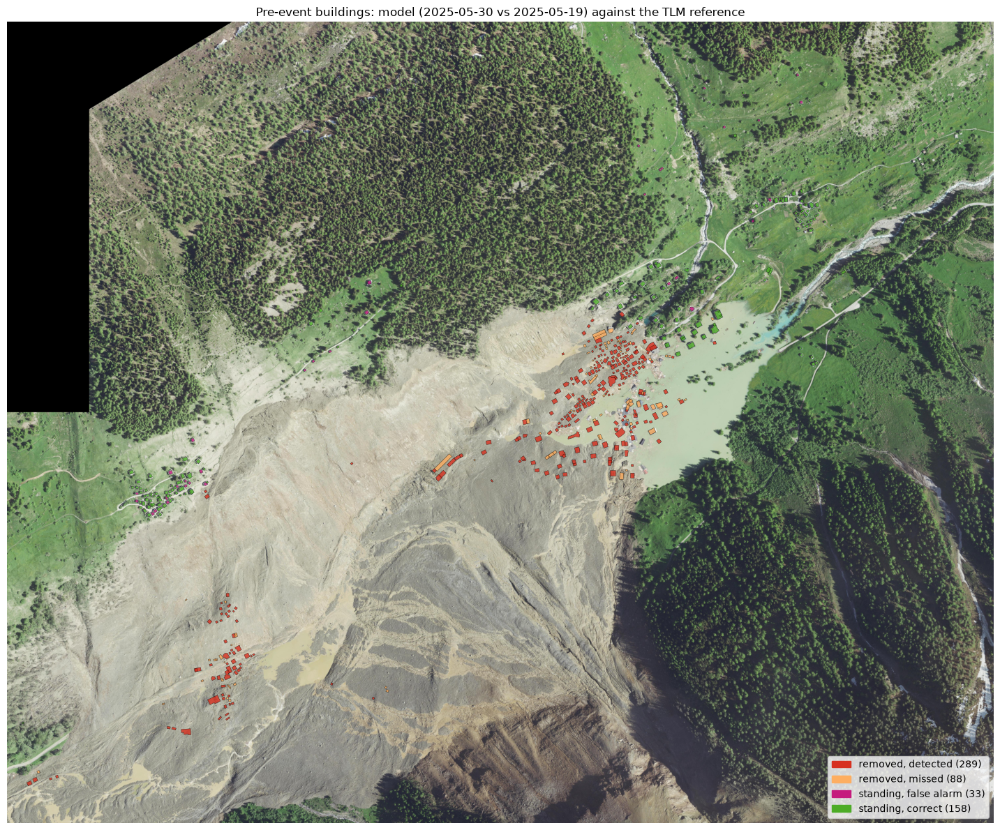

In [12]:
fig, ax = plt.subplots(figsize=(16, 12))
ax.imshow(rgb(post), extent=extent)
colours = {("removed", "changed"): "#d7301f", ("removed", "unchanged"): "#fdae61",
           ("standing", "changed"): "#c51b7d", ("standing", "unchanged"): "#4dac26"}
labels = {("removed", "changed"): "removed, detected", ("removed", "unchanged"): "removed, missed",
          ("standing", "changed"): "standing, false alarm", ("standing", "unchanged"): "standing, correct"}
evaluable = buildings_out[buildings_out.evaluable]
for key, group in evaluable.groupby(["reference", "model"]):
    group.plot(ax=ax, facecolor=colours[key], edgecolor="black", linewidth=0.3, alpha=0.8)
ax.legend(handles=[Patch(color=c, label=f"{labels[k]} ({len(evaluable.groupby(['reference', 'model']).groups.get(k, []))})")
                   for k, c in colours.items()], loc="lower right")
ax.set_title(f"Pre-event buildings: model ({POST} vs {PRE}) against the TLM reference")
ax.set_axis_off()
plt.tight_layout()
plt.savefig(FIGURES / "03_building_assessment.png", dpi=150, bbox_inches="tight")
plt.show()

## I. Spot-checks (page 9)

Four zooms: the village core under the debris, the flooded east of
the village, the hamlet of Ried under the debris, and Weissenried (unaffected).

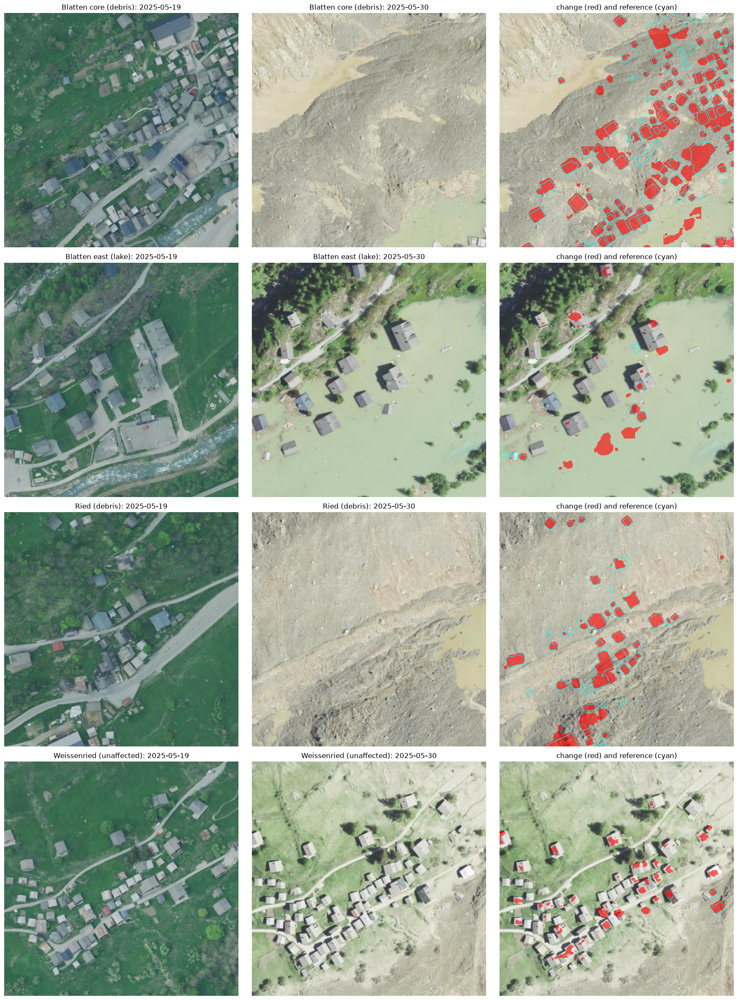

In [13]:
def window_around(x, y, size_m=200):
    """Row/col slices of a square window of `size_m` metres around an LV95 point."""
    col, row = ~transform * (x, y)
    half = int(size_m / transform.a / 2)
    return slice(max(int(row) - half, 0), int(row) + half), slice(max(int(col) - half, 0), int(col) + half)


spots = {"Blatten core (debris)": (2629200, 1141100), "Blatten east (lake)": (2629500, 1141200),
         "Ried (debris)": (2628350, 1140400), "Weissenried (unaffected)": (2628200, 1140820)}
fig, axes = plt.subplots(len(spots), 3, figsize=(18, 6 * len(spots)))
for row, (name, (x, y)) in enumerate(spots.items()):
    rows, cols = window_around(x, y)
    axes[row, 0].imshow(rgb(pre)[rows, cols])
    axes[row, 0].set_title(f"{name}: {PRE}")
    axes[row, 1].imshow(rgb(post)[rows, cols])
    axes[row, 1].set_title(f"{name}: {POST}")
    axes[row, 2].imshow(rgb(post)[rows, cols])
    axes[row, 2].imshow(np.ma.masked_equal(change_map[rows, cols], 0), cmap="autumn", alpha=0.6, interpolation="nearest")
    axes[row, 2].contour(reference_change[rows, cols], levels=[0.5], colors="cyan", linewidths=0.8)
    axes[row, 2].set_title("change (red) and reference (cyan)")
for ax in axes.flat:
    ax.set_axis_off()
plt.tight_layout()
plt.savefig(FIGURES / "03_spot_checks.png", dpi=110, bbox_inches="tight")
plt.show()

**What the spot-checks show.**

- *Blatten core and Ried (debris):* almost every house under the debris is flagged, and the blobs sit on
  the reference footprints. Missed buildings tend to be smaller than detected ones (median 28 vs
  42 m²); many of them lie in the eastern part of the village next to the lake (see the building map).
- *Blatten east (lake):* the model flags only some of the flooded houses. Many roofs are still visible
  above the water on 30 May, so "no change" is a defensible answer for the image, even if TLM later
  removed them. Some blobs lie on open water, where floating objects or turbid patches appeared.
- *Weissenried (unaffected):* small blobs appear on many roofs, caused by the strong difference in
  colour and illumination between the two flights, but they cover only parts of roofs, so almost no
  standing building crosses the 50% rule.

## J. Which pre-event image? A comparison of dates (page 9)

The model was trained on SWISSIMAGE 2023. Using SWISSIMAGE 2023 as T1 instead of the 19 May quick
orthophoto puts T1 in the training domain, but spans two years and a different season. Both are
legitimate choices; this cell shows how much the choice of T1 matters.

In [14]:
valid_2023 = (swissimage.max(axis=0) > 0) & (post.max(axis=0) > 0)
prob_2023 = predict_change(swissimage, post)
map_2023 = (prob_2023 > THRESHOLD) & valid_2023 & valid  # same evaluation area as above
_, buildings_2023 = building_scores(map_2023)


def summary_row(pred, buildings):
    pixels = pixel_scores(pred, reference_change)
    return {"pixel F1": pixels["F1-score"], "pixel IoU": pixels["IoU"],
            **{f"building {k}" if k in ("Precision", "Recall", "F1-score") else k: v for k, v in buildings.items()}}


dates_table = pd.DataFrame({
    f"T1 = Rapid Mapping {PRE}": summary_row(change_map, building_result),
    "T1 = SWISSIMAGE 2023": summary_row(map_2023, buildings_2023),
}).T
dates_table.to_csv(OUT_DIR / "evaluation_pre_image_choice.csv")
dates_table.round(3)

,pixel F1,pixel IoU,"removed, detected (TP)","standing, flagged (FP)","removed, missed (FN)","standing, not flagged (TN)",building Precision,building Recall,building F1-score
T1 = Rapid Mapping 2025-05-19,0.436,0.279,289.0,33.0,88.0,158.0,0.898,0.767,0.827
T1 = SWISSIMAGE 2023,0.662,0.494,300.0,6.0,77.0,185.0,0.980,0.796,0.878


**Comparison.** Using SWISSIMAGE 2023 as T1 is *better* on every score (building F1 0.88
instead of 0.83; only 6 standing buildings flagged instead of 33), over the same evaluation area. The
model was trained on SWISSIMAGE, so its T1 branch is in its training domain, while the 19 May quick
orthophoto differs in colour and still shows snow on the shaded slopes. The two-year gap matters little
here, because building change before the event was rare compared to the destruction. Both results are
reported; the 19 May pair remains the main result because it is the true "just before" image.

## K. Project summary (page 9 deliverable)

| | |
|---|---|
| **Change** | Buildings removed (destroyed or buried) by the 28 May 2025 ice-rock avalanche, Blatten |
| **Images** | swisstopo Rapid Mapping 19 May (pre) and 30 May 2025 (post), 0.5 m; SWISSIMAGE 2023 as alternative T1 |
| **Method** | FC-Siam-diff (ResNet18, ImageNet), TorchGeo `ChangeDetection`, trained on SWISSIMAGE 2023 + swissTLM3D 2025-03 with synthetic pairs; 3 seeds on a Colab GPU, seed 0 selected by validation F1 |
| **Threshold** | 0.02, chosen on the validation area (Wiler); flat F1 curve, so the choice matters little |
| **Validation** | Pre-event footprints removed in swissTLM3D 2026-02 as independent reference |
| **Result** | 289 / 377 removed buildings detected, 33 / 191 standing flagged: building F1 0.83 (0.88 with T1 = SWISSIMAGE 2023) |
| **Seeds** | Building F1 0.81 ± 0.02 over the three seeds (0.86 ± 0.02 with T1 = SWISSIMAGE 2023); tables in `outputs/results/seeds/` |
| **Main errors** | Snow melt, debris and lake surfaces flagged as change; flooded houses with visible roofs missed |

See `README.md` for the half-page project plan, setup and caveats.